# 01 - Données : ModelNet10 vers nuages de points

**Objectif.** Transformer des maillages 3D (`.off`) en nuages de **1 024 points** normalisés, pour 3 catégories (chaise, table, canapé), puis sauvegarder le résultat dans un seul fichier `.npz`.

Étapes :
1. Configuration (Colab ou local)
2. Téléchargement de ModelNet10
3. Lecture des fichiers `.off` et échantillonnage de points sur la surface
4. Normalisation (centrage + rayon 1)
5. Construction et sauvegarde du jeu de données
6. Visualisation et statistiques (pour le rapport)

## 1. Configuration

In [1]:
import sys, csv, zipfile, subprocess, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

REPO_URL = "https://github.com/Hdlmrbt/3d-generation-reconstruction.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Sur Colab : on clone le dépôt (si privé, le clone échoue et on crée un dossier vide)
    ROOT = Path("/content/3d-generation-reconstruction")
    if not ROOT.exists():
        r = subprocess.run(["git", "clone", REPO_URL, str(ROOT)])
        if r.returncode != 0:
            ROOT.mkdir(parents=True, exist_ok=True)
else:
    # En local : ce notebook est dans notebooks/, la racine du projet est un cran au-dessus
    ROOT = Path("..").resolve()

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
for d in (RAW, PROCESSED, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Paramètres de l'expérience
CATEGORIES = ["chair", "table", "sofa"]
N_POINTS = 1024      # points par objet
MAX_TRAIN = 400      # objets d'entraînement max par catégorie
MAX_TEST = 100       # objets de test max par catégorie
SEED = 42
rng = np.random.default_rng(SEED)

print("Racine du projet :", ROOT)

c:\Users\Lenovo\Documents\emsi5\AI_visuelle\Projet6\3d-generation-reconstruction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Racine du projet : C:\Users\Lenovo\Documents\emsi5\AI_visuelle\Projet6\3d-generation-reconstruction


## 2. Téléchargement de ModelNet10

Le fichier fait environ 470 Mo. Si le lien officiel ne répond pas (il est parfois hors service), téléchargez le jeu depuis Kaggle (recherche : *ModelNet10 Princeton 3D Object Dataset*), puis placez le dossier `ModelNet10/` dans `data/raw/`.

In [2]:
import time, urllib.error

def download(url, dest, retries=30, chunk=1 << 20):
    """Télécharge avec reprise automatique si la connexion est coupée."""
    dest = Path(dest)
    part = dest.with_suffix(dest.suffix + ".part")
    for attempt in range(1, retries + 1):
        done = part.stat().st_size if part.exists() else 0
        headers = {"Range": f"bytes={done}-"} if done else {}
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=30) as r:
                if done and r.status != 206:      # le serveur ne gère pas la reprise : on repart de zéro
                    part.unlink()
                    done = 0
                total = done + int(r.headers.get("Content-Length", 0))
                with open(part, "ab" if done else "wb") as f, \
                     tqdm(total=total, initial=done, unit="B", unit_scale=True) as bar:
                    while True:
                        buf = r.read(chunk)
                        if not buf:
                            break
                        f.write(buf)
                        bar.update(len(buf))
            if part.stat().st_size >= total:
                part.rename(dest)
                return dest
        except urllib.error.HTTPError as e:
            if e.code == 416 and zipfile.is_zipfile(part):   # déjà complet
                part.rename(dest)
                return dest
            print(f"Tentative {attempt}: erreur HTTP {e.code}")
        except Exception as e:
            print(f"Tentative {attempt}: connexion interrompue ({type(e).__name__}), reprise...")
        time.sleep(2)
    raise RuntimeError("Échec du téléchargement après plusieurs tentatives")


URL = "http://3dvision.princeton.edu/projects/2014/3DShapeNets/ModelNet10.zip"
zip_path = RAW / "ModelNet10.zip"
data_dir = RAW / "ModelNet10"

if not data_dir.exists():
    if not zip_path.exists():
        print("Téléchargement en cours...")
        download(URL, zip_path)
    print("Décompression...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW)

print("Catégories disponibles :", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

Catégories disponibles : ['bathtub', 'bed', 'chair', 'desk', 'dresser', 'monitor', 'night_stand', 'sofa', 'table', 'toilet']


## 3. Lire un maillage et échantillonner des points

Un maillage est un ensemble de **sommets** (points 3D) et de **triangles** (qui relient 3 sommets). Pour obtenir un nuage de points qui couvre bien la surface, on choisit des triangles **avec une probabilité proportionnelle à leur aire** (sinon les petits triangles seraient sur-représentés), puis un point au hasard dans chaque triangle choisi.

In [3]:
def read_off(path):
    """Lit un fichier .off et renvoie (sommets [V,3], faces [F,3]).
    Gère le cas fréquent dans ModelNet où l'en-tête est collé : 'OFF490 518 0'."""
    with open(path, "r") as f:
        tokens = f.read().replace("OFF", " ", 1).split()
    n_v, n_f = int(tokens[0]), int(tokens[1])
    vertices = np.array(tokens[3:3 + 3 * n_v], dtype=np.float64).reshape(n_v, 3)
    faces, idx = [], 3 + 3 * n_v
    for _ in range(n_f):
        k = int(tokens[idx])
        faces.append([int(x) for x in tokens[idx + 1: idx + 4]])  # on garde les 3 premiers indices
        idx += k + 1
    return vertices, np.array(faces, dtype=np.int64)


def sample_surface(vertices, faces, n_points, rng):
    """Échantillonne n_points sur la surface, uniformément par rapport à l'aire."""
    v0, v1, v2 = vertices[faces[:, 0]], vertices[faces[:, 1]], vertices[faces[:, 2]]
    areas = 0.5 * np.linalg.norm(np.cross(v1 - v0, v2 - v0), axis=1)
    assert areas.sum() > 0, "maillage dégénéré (aire nulle)"
    tri = rng.choice(len(faces), size=n_points, p=areas / areas.sum())
    r1, r2 = rng.random(n_points), rng.random(n_points)
    s = np.sqrt(r1)
    a, b, c = 1 - s, s * (1 - r2), s * r2          # coordonnées barycentriques
    return a[:, None] * v0[tri] + b[:, None] * v1[tri] + c[:, None] * v2[tri]


def normalize(points):
    """Centre le nuage à l'origine et le met à l'échelle pour que le point le plus éloigné soit à distance 1."""
    points = points - points.mean(axis=0)
    return points / np.linalg.norm(points, axis=1).max()


def off_to_cloud(path, n_points, rng):
    v, f = read_off(path)
    return normalize(sample_surface(v, f, n_points, rng)).astype(np.float32)

## 4. Construire le jeu de données (train / test)

In [4]:
def load_split(category, split, max_n):
    files = sorted((data_dir / category / split).glob("*.off"))
    if len(files) > max_n:
        keep = np.sort(rng.choice(len(files), size=max_n, replace=False))
        files = [files[i] for i in keep]
    clouds = [off_to_cloud(p, N_POINTS, rng) for p in tqdm(files, desc=f"{category}/{split}")]
    return np.stack(clouds)


X_train, y_train, X_test, y_test = [], [], [], []
for label, cat in enumerate(CATEGORIES):
    tr = load_split(cat, "train", MAX_TRAIN)
    te = load_split(cat, "test", MAX_TEST)
    X_train.append(tr); y_train += [label] * len(tr)
    X_test.append(te);  y_test += [label] * len(te)

X_train, X_test = np.concatenate(X_train), np.concatenate(X_test)
y_train, y_test = np.array(y_train), np.array(y_test)

out_file = PROCESSED / f"modelnet10_{len(CATEGORIES)}cat_{N_POINTS}.npz"
np.savez_compressed(out_file, X_train=X_train, y_train=y_train,
                    X_test=X_test, y_test=y_test, categories=np.array(CATEGORIES))
print("Sauvegardé :", out_file, f"({out_file.stat().st_size / 1e6:.1f} Mo)")

sofa/test: 100%|██████████| 100/100 [00:07<00:00, 14.13it/s]


Sauvegardé : C:\Users\Lenovo\Documents\emsi5\AI_visuelle\Projet6\3d-generation-reconstruction\data\processed\modelnet10_3cat_1024.npz (15.1 Mo)


## 5. Vérifications et statistiques

In [5]:
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Rayon max (doit être 1.0) :", np.linalg.norm(X_train, axis=2).max())
print("Centre moyen (doit être ~0) :", np.abs(X_train.mean(axis=1)).max())

rows = [["categorie", "train", "test"]]
for label, cat in enumerate(CATEGORIES):
    rows.append([cat, int((y_train == label).sum()), int((y_test == label).sum())])
rows.append(["total", len(X_train), len(X_test)])
for r in rows:
    print(f"{r[0]:<10}{r[1]:>8}{r[2]:>8}")

with open(TAB_DIR / "01_dataset_stats.csv", "w", newline="") as f:
    csv.writer(f).writerows(rows)

X_train : (1192, 1024, 3) | X_test : (300, 1024, 3)
Rayon max (doit être 1.0) : 1.0
Centre moyen (doit être ~0) : 1.0288204e-07
categorie    train    test
chair          400     100
table          392     100
sofa           400     100
total         1192     300


## 6. Visualisation

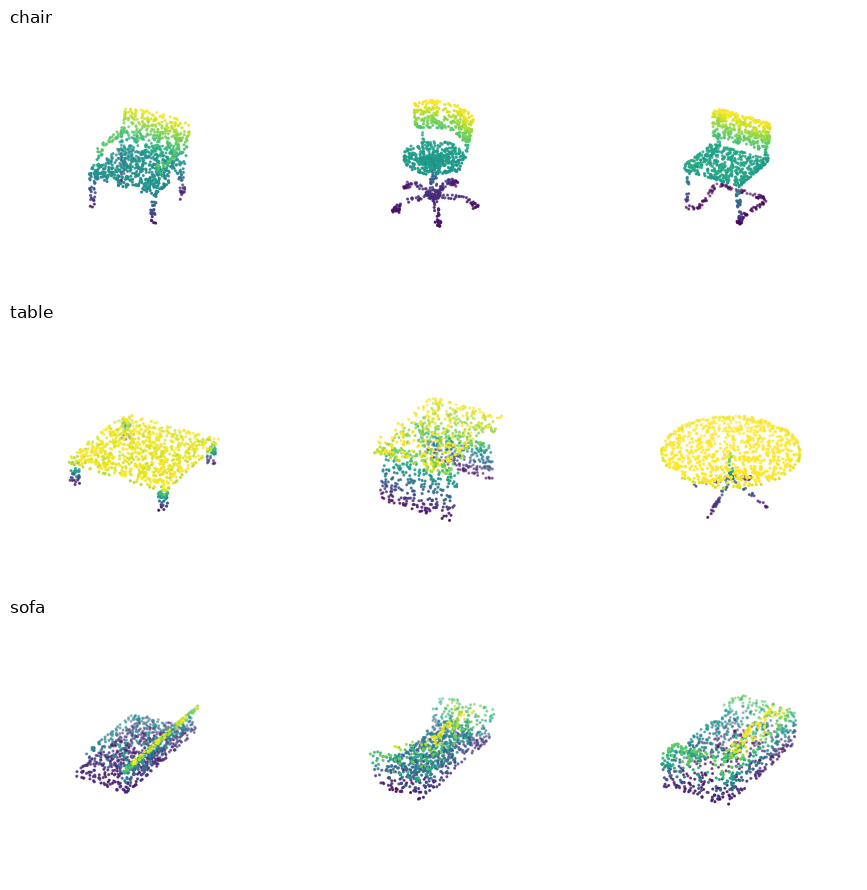

In [6]:
# Figure statique pour le rapport : 3 exemples par catégorie
fig = plt.figure(figsize=(9, 9))
for i, cat in enumerate(CATEGORIES):
    ids = np.where(y_train == i)[0][:3]
    for j, k in enumerate(ids):
        ax = fig.add_subplot(len(CATEGORIES), 3, i * 3 + j + 1, projection="3d")
        p = X_train[k]
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1.5, c=p[:, 2], cmap="viridis")
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_axis_off()
        if j == 0:
            ax.set_title(cat, loc="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_examples.png", dpi=150)
plt.show()

In [7]:
# Version interactive (on peut tourner l'objet avec la souris)
import plotly.graph_objects as go

def show_cloud(points, title=""):
    fig = go.Figure(go.Scatter3d(
        x=points[:, 0], y=points[:, 1], z=points[:, 2], mode="markers",
        marker=dict(size=2, color=points[:, 2], colorscale="Viridis")))
    fig.update_layout(title=title, scene=dict(aspectmode="data"), height=500, margin=dict(l=0, r=0, b=0, t=40))
    fig.show()

idx = 0
show_cloud(X_train[idx], CATEGORIES[y_train[idx]])

## Résumé

- Jeu de données prêt : `data/processed/modelnet10_3cat_1024.npz` (non versionné dans Git, voir `.gitignore`).
- Figure : `results/figures/01_examples.png`. Tableau : `results/tables/01_dataset_stats.csv`.

**Suite :** `02_baseline.ipynb`, un autoencodeur PointNet avec distance de Chamfer.